kurulum ve veriyi yükleme

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Dosyayı yükle (Colab)
from google.colab import files
uploaded = files.upload()          # StudentsPerformance.csv'yi seçin

df = pd.read_csv("StudentsPerformance.csv")
df.head()

Saving StudentsPerformance.csv to StudentsPerformance (1).csv


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


EDA

In [7]:
#2.1 Genel bilgi
print(df.shape)
df.info()
print("\nEksik değer:\n", df.isna().sum())
print("\nTekrar eden satır:", df.duplicated().sum())
df.describe()

(1000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Eksik değer:
 gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score     

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [8]:
# 2.2 Kategorik değişkenlerin dağılımı
kat_cols = df.select_dtypes(include="object").columns
for c in kat_cols:
    print(df[c].value_counts(), "\n")

gender
female    518
male      482
Name: count, dtype: int64 

race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64 

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64 

lunch
standard        645
free/reduced    355
Name: count, dtype: int64 

test preparation course
none         642
completed    358
Name: count, dtype: int64 



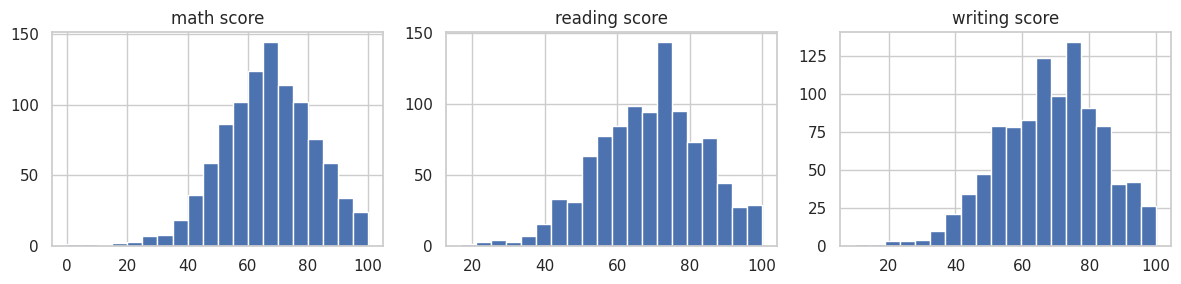

In [9]:
# 2.3 Sayısal değişkenlerin dağılımı
sayisal = ["math score", "reading score", "writing score"]
df[sayisal].hist(bins=20, figsize=(12, 3), layout=(1, 3))
plt.tight_layout(); plt.show()

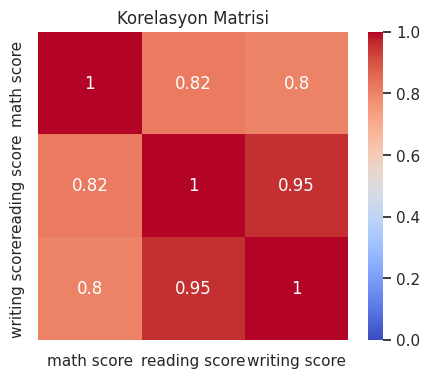

In [10]:
# 2.4 Korelasyon
plt.figure(figsize=(5, 4))
sns.heatmap(df[sayisal].corr(), annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Korelasyon Matrisi"); plt.show()

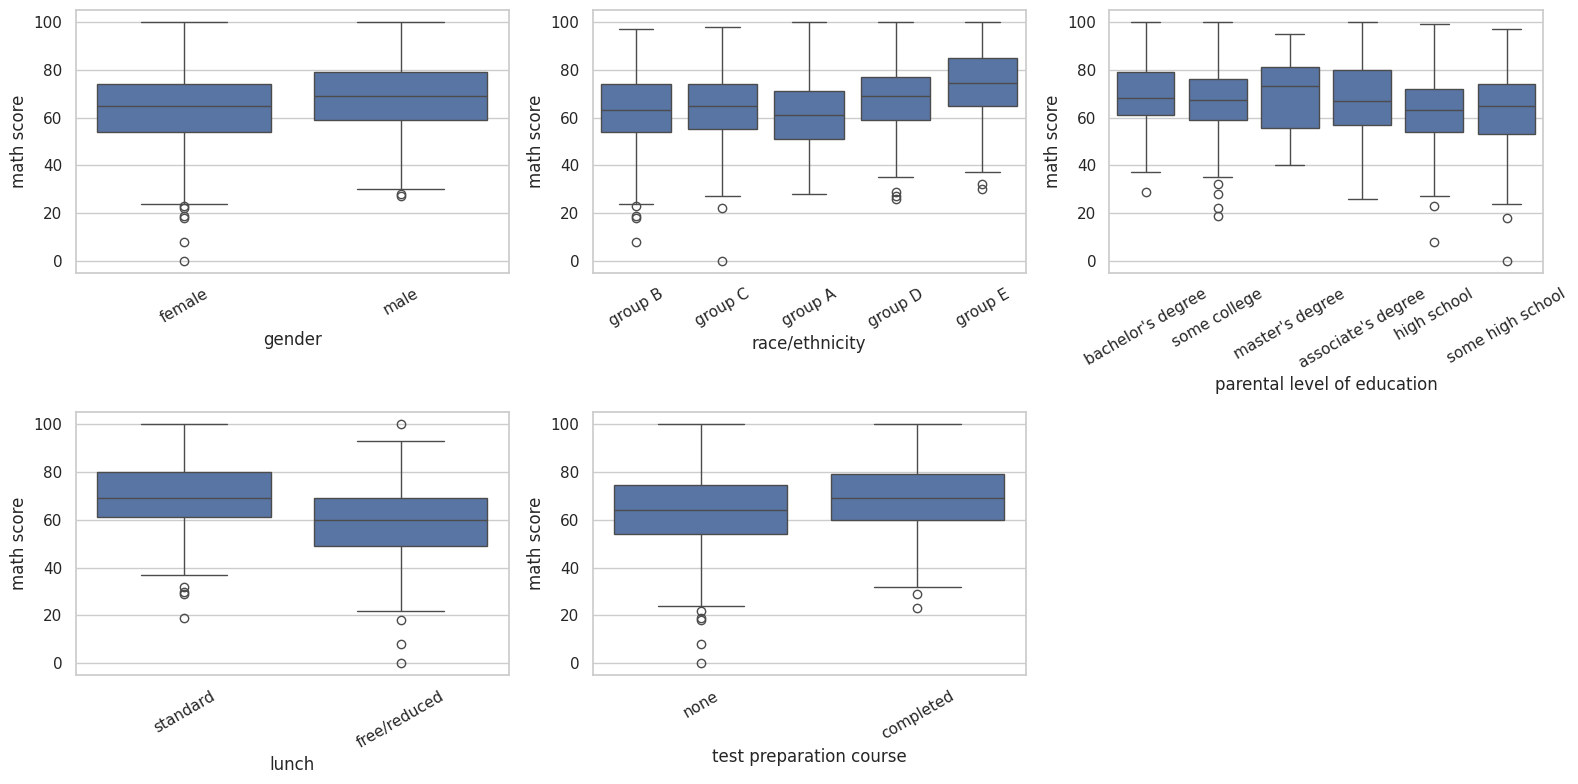

In [11]:
# 2.5 Kategorilere göre matematik skoru
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), kat_cols):
    sns.boxplot(data=df, x=c, y="math score", ax=ax)
    ax.tick_params(axis="x", rotation=30)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

Veri temizleme ve aykırı değer kontrolü

In [12]:
# Sütun adlarını kodlamaya uygun hale getir
df.columns = (df.columns.str.strip().str.replace("/", "_").str.replace(" ", "_"))
print(df.columns.tolist())

# IQR yöntemiyle aykırı değer sayısı
for c in ["math_score", "reading_score", "writing_score"]:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    alt, ust = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[c] < alt) | (df[c] > ust)).sum()
    print(f"{c}: {n} aykırı değer (sınırlar: {alt:.1f} - {ust:.1f})")

df[df["math_score"] < 20]

['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']
math_score: 8 aykırı değer (sınırlar: 27.0 - 107.0)
reading_score: 6 aykırı değer (sınırlar: 29.0 - 109.0)
writing_score: 5 aykırı değer (sınırlar: 25.9 - 110.9)


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
787,female,group B,some college,standard,none,19,38,32
980,female,group B,high school,free/reduced,none,8,24,23


Hedef ve özelliklerin belirlenmesi

In [13]:
HEDEF = "math_score"
KULLAN_SKORLAR = True   # False yaparsanız reading/writing skorları modele girmez

ordinal_col = ["parental_level_of_education"]
nominal_cols = ["gender", "race_ethnicity", "lunch", "test_preparation_course"]
sayisal_cols = ["reading_score", "writing_score"] if KULLAN_SKORLAR else []

X = df[ordinal_col + nominal_cols + sayisal_cols]
y = df[HEDEF]
print(X.shape, y.shape)

(1000, 7) (1000,)


Eğitim / test ayırma

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Eğitim:", X_train.shape, "Test:", X_test.shape)

Eğitim: (800, 7) Test: (200, 7)


Ön işleme (kodlama ve ölçekleme)

Modeller metin anlamaz, sayı ister.

Ordinal kodlama: Ebeveyn eğitimi sıralıdır (ilkokul < lise < lisans...).

Sırayı koruyarak 0-5 arası sayıya çeviriyoruz.
One-hot kodlama: Cinsiyet, grup gibi sırasız kategorileri 0/1 sütunlarına açıyoruz.
Ölçekleme: Doğrusal modellerde (Ridge, Lasso) özelliklerin aynı ölçekte olması gerekir. Ağaç modelleri için şart değildir ama zararı da yoktur.

Hepsini ColumnTransformer ile tek bir yapıda topluyoruz.



In [15]:
egitim_sirasi = [["some high school", "high school", "some college",
                  "associate's degree", "bachelor's degree", "master's degree"]]

preprocess = ColumnTransformer(transformers=[
    ("ord", OrdinalEncoder(categories=egitim_sirasi), ordinal_col),
    ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore"), nominal_cols),
    ("num", StandardScaler(), sayisal_cols),
])

Model kurma ve karşılaştırma

Farklı karmaşıklıkta birkaç modeli aynı Pipeline içinde deniyoruz.

Linear Regression: basit referans (baseline)
Ridge / Lasso: düzenlileştirilmiş doğrusal modeller (aşırı öğrenmeyi azaltır)
Random Forest / Gradient Boosting: doğrusal olmayan ilişkileri yakalayan topluluk modelleri

Karşılaştırmayı 5 katlı çapraz doğrulama (CV) ile yapıyoruz. Tek bir train/test bölmesine güvenmek yerine, modelin farklı veri parçalarındaki kararlılığına bakıyoruz.

In [16]:
modeller = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
sonuclar = []

for isim, model in modeller.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
    rmse = -cross_val_score(pipe, X_train, y_train, cv=kf,
                            scoring="neg_root_mean_squared_error")
    sonuclar.append({"Model": isim,
                     "CV R² (ort)": r2.mean(), "CV R² (std)": r2.std(),
                     "CV RMSE (ort)": rmse.mean()})

pd.DataFrame(sonuclar).sort_values("CV R² (ort)", ascending=False).round(3)

,Model,CV R² (ort),CV R² (std),CV RMSE (ort)
1,Ridge,0.869,0.015,5.396
0,Linear Regression,0.869,0.015,5.397
2,Lasso,0.868,0.015,5.421
4,Gradient Boosting,0.851,0.019,5.763
3,Random Forest,0.838,0.019,6.010


Hiperparametre ayarı

En iyi çıkan modelin ayarlarını (hiperparametreler) GridSearchCV ile sistematik olarak deniyoruz. Örnek olarak Ridge ve Random Forest veriyorum. CV sonucunda hangisi öndeyse onu kullanın.(Bizde ridge ve linear regression)

In [17]:
# Örnek 1: Ridge
pipe_ridge = Pipeline([("prep", preprocess), ("model", Ridge())])
grid_ridge = GridSearchCV(
    pipe_ridge,
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=kf, scoring="r2", n_jobs=-1
)
grid_ridge.fit(X_train, y_train)
print("Ridge en iyi:", grid_ridge.best_params_, "CV R²:", round(grid_ridge.best_score_, 3))

# Örnek 2: Random Forest
pipe_rf = Pipeline([("prep", preprocess),
                    ("model", RandomForestRegressor(random_state=42))])
grid_rf = GridSearchCV(
    pipe_rf,
    param_grid={
        "model__n_estimators": [100, 300],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [1, 5, 10],
    },
    cv=kf, scoring="r2", n_jobs=-1
)
grid_rf.fit(X_train, y_train)
print("RF en iyi:", grid_rf.best_params_, "CV R²:", round(grid_rf.best_score_, 3))

Ridge en iyi: {'model__alpha': 1} CV R²: 0.869
RF en iyi: {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 300} CV R²: 0.84


Test verisinde son değerlendirme

Test setine yalnızca bir kez, seçtiğimiz nihai modelle bakıyoruz. Metrikler:

MAE: ortalama mutlak hata (puan cinsinden)
RMSE: büyük hataları daha çok cezalandırır
R²: varyansın ne kadarının açıklandığı (1'e yakın iyi)

In [18]:
en_iyi_model = grid_ridge.best_estimator_     # CV'de en iyi olanı seçin

y_pred = en_iyi_model.predict(X_test)

print(f"MAE : {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
print(f"R²  : {r2_score(y_test, y_pred):.3f}")

MAE : 4.18
RMSE: 5.37
R²  : 0.882


Hata analizi ve görselleştirme

Metriklerin görmediği şeyleri grafikle kontrol ediyoruz. Tahmin ve gerçek değerler çizgiye yakın mı? Artıklar (residual) rastgele dağılıyor mu?

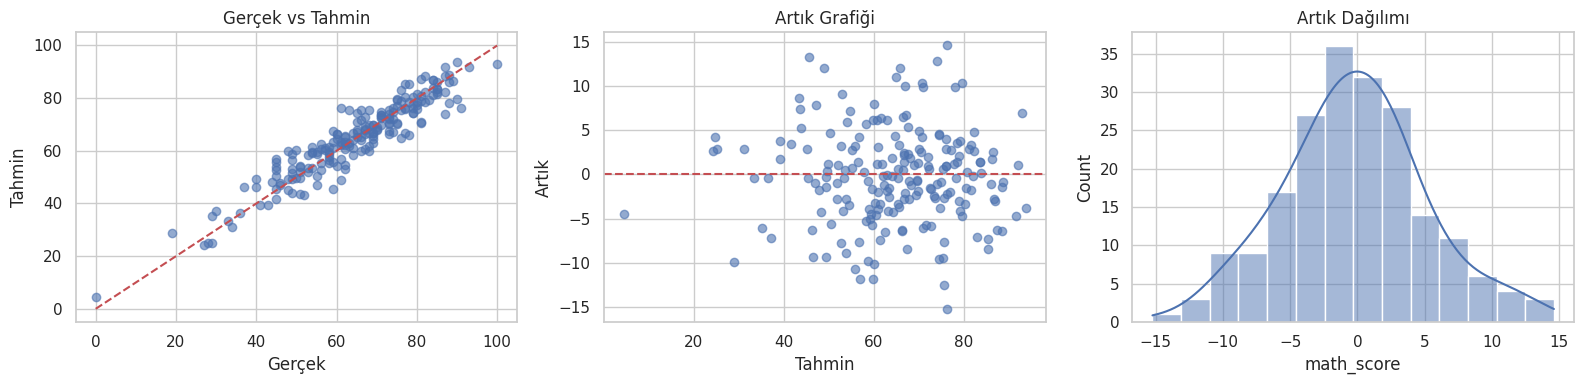

In [19]:
artik = y_test - y_pred

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].scatter(y_test, y_pred, alpha=.6)
ax[0].plot([0, 100], [0, 100], "r--")
ax[0].set(xlabel="Gerçek", ylabel="Tahmin", title="Gerçek vs Tahmin")

ax[1].scatter(y_pred, artik, alpha=.6)
ax[1].axhline(0, color="r", ls="--")
ax[1].set(xlabel="Tahmin", ylabel="Artık", title="Artık Grafiği")

sns.histplot(artik, kde=True, ax=ax[2])
ax[2].set(title="Artık Dağılımı")

plt.tight_layout(); plt.show()

Özellik önemi

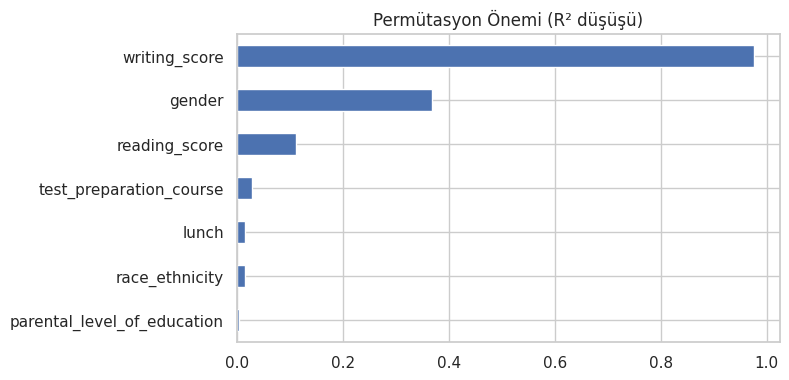

In [20]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(en_iyi_model, X_test, y_test,
                            n_repeats=20, random_state=42, scoring="r2")

onem = (pd.Series(pi.importances_mean, index=X_test.columns)
          .sort_values())
onem.plot(kind="barh", figsize=(7, 4), title="Permütasyon Önemi (R² düşüşü)")
plt.show()

Modeli kaydetme ve yeni veriyle tahmin

**Joblib**, Python'da büyük veri kümelerini, NumPy dizilerini ve makine öğrenmesi modellerini disk üzerine hızlıca kaydetmek, yüklemek ve paralel hesaplamalarla işlem hızını artırmak için kullanılan hafif ve güçlü bir kütüphanedir

In [21]:
import joblib
joblib.dump(en_iyi_model, "math_score_model.pkl")
files.download("math_score_model.pkl")

# Yeni tahmin örneği
model = joblib.load("math_score_model.pkl")
yeni = pd.DataFrame([{
    "parental_level_of_education": "bachelor's degree",
    "gender": "female",
    "race_ethnicity": "group C",
    "lunch": "standard",
    "test_preparation_course": "completed",
    "reading_score": 80,        # KULLAN_SKORLAR=False ise bu iki satırı silin
    "writing_score": 78,
}])
print("Tahmini matematik skoru:", model.predict(yeni)[0].round(1))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tahmini matematik skoru: 67.0


Ek bölüm: Sınıflandırma versiyonu (geçti / kaldı)

gecti
1    0.677
0    0.323
Name: proportion, dtype: float64
              precision    recall  f1-score   support

       Kaldı       0.91      0.77      0.83        65
       Geçti       0.90      0.96      0.93       135

    accuracy                           0.90       200
   macro avg       0.90      0.87      0.88       200
weighted avg       0.90      0.90      0.90       200



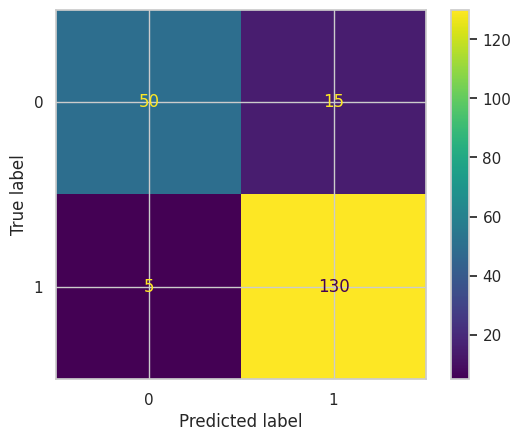

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

df["gecti"] = (df["math_score"] >= 60).astype(int)
print(df["gecti"].value_counts(normalize=True))   # sınıf dengesini kontrol et

Xc = df[ordinal_col + nominal_cols + sayisal_cols]
yc = df["gecti"]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc   # stratify: oranı korur
)

clf = Pipeline([("prep", preprocess),
                ("model", LogisticRegression(max_iter=1000))])
clf.fit(Xc_tr, yc_tr)
yc_pred = clf.predict(Xc_te)

print(classification_report(yc_te, yc_pred, target_names=["Kaldı", "Geçti"]))
ConfusionMatrixDisplay.from_predictions(yc_te, yc_pred); plt.show()